##Upload File Excel

In [27]:
from google.colab import files
uploaded = files.upload()

Saving Pertemuan1_AlifFatan.xlsx to Pertemuan1_AlifFatan (1).xlsx


## 1. Pengorganisasian Data

In [41]:
import pandas as pd

path = "Pertemuan1_AlifFatan.xlsx"
dataraw = pd.read_excel(path)
display(dataraw)

,Unnamed: 0,ID,Name,Marks in Quiz\n (Out of 100),Mid Term Results (Out of 100),Final Term Resul (Out of 100),Final Score,Grade
0,NaN,2455301020,Alif Fatan Ahlaqi,93,82,95,90.07,A
1,NaN,120001,John Doe,85,78,90,84.44,A
2,NaN,120005,Jane Smith,92,88,94,91.38,A
3,NaN,120017,Michael Johnson,48,65,56,56.41,C
4,NaN,120018,Emily Brown,90,85,88,87.65,A
5,NaN,120022,Daniel Martinez,75,80,77,77.35,AB
6,NaN,120024,Sarah Wilson,88,70,65,74.01,B
7,NaN,120025,David Garcia,75,70,75,73.35,B
8,NaN,120027,Jessica Lee,95,91,96,94.03,A
9,NaN,120034,Matthew Davis,79,84,78,80.30,AB


## 2. Penyajian Data

In [42]:
datafrq = pd.crosstab(index=dataraw["Grade"], columns="Frekuensi")
print(datafrq)

col_0  Frekuensi
Grade           
A             13
AB             7
B              4
BC             1
C              5
F              1


>### Grafik Garis

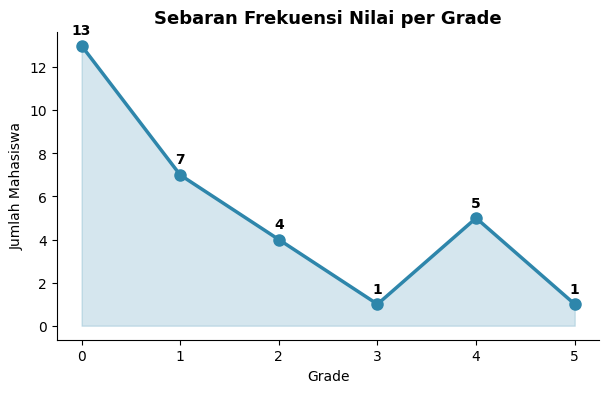

In [43]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7,4))

x = datafreq.index
y = datafreq['Frekuensi']

ax.plot(x, y, marker='o', markersize=8, color='#2E86AB', linewidth=2.5)
ax.fill_between(x, y, color='#2E86AB', alpha=0.2)

for xi, yi in zip(x, y):
    ax.annotate(str(yi), (xi, yi), textcoords="offset points", xytext=(0,8), ha='center', fontweight='bold')

ax.set_title("Sebaran Frekuensi Nilai per Grade", fontsize=13, fontweight='bold')
ax.set_ylabel("Jumlah Mahasiswa")
ax.set_xlabel("Grade")
ax.spines[['top','right']].set_visible(False)
plt.show()

>### Grafik Batang

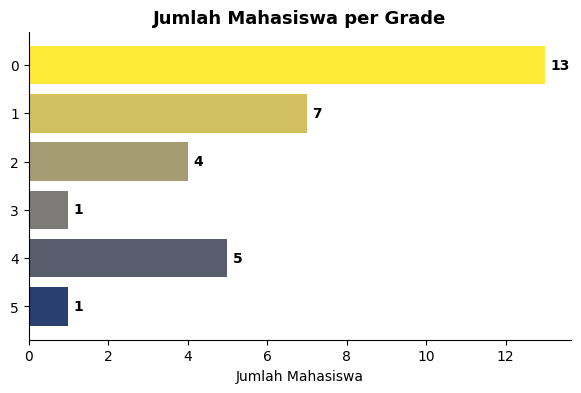

In [44]:
plt.style.use('default')

fig, ax = plt.subplots(figsize=(7,4))

colors = [plt.cm.cividis_r(i / len(datafreq)) for i in range(len(datafreq))]

bars = ax.barh(datafreq.index.astype(str), datafreq['Frekuensi'], color=colors)
ax.bar_label(bars, padding=4, fontweight='bold')

ax.set_title("Jumlah Mahasiswa per Grade", fontsize=13, fontweight='bold')
ax.set_xlabel("Jumlah Mahasiswa")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.invert_yaxis()

plt.show()

>### Pie Chart

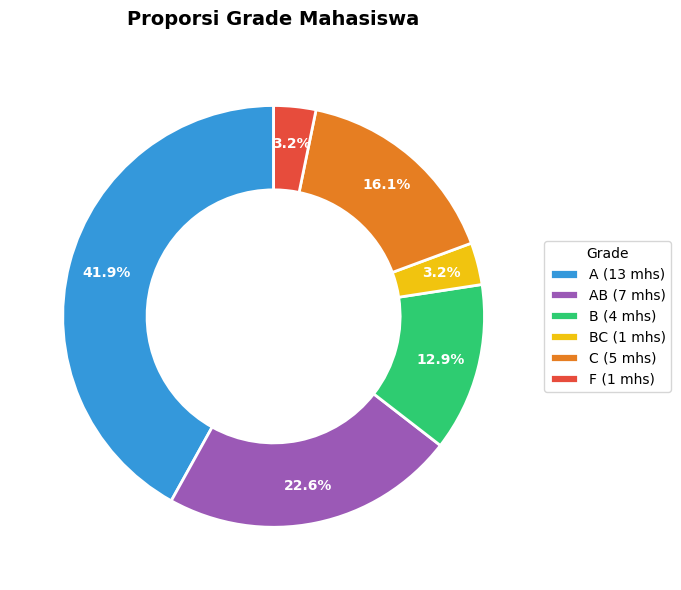

In [45]:
plt.style.use('default')

fig, ax = plt.subplots(figsize=(8,6))
freq = datafrq['Frekuensi']
colors = ['#3498DB', '#9B59B6', '#2ECC71', '#F1C40F', '#E67E22', '#E74C3C']

wedges, texts, autotexts = ax.pie(
    freq, autopct='%1.1f%%', startangle=90,
    colors=colors[:len(freq)], pctdistance=0.82,
    wedgeprops={'width':0.4, 'edgecolor':'white', 'linewidth':2}
)

for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')
    at.set_fontsize(10)

ax.legend(wedges, [f"{g} ({v} mhs)" for g, v in zip(freq.index, freq)],
          title="Grade", loc="center left", bbox_to_anchor=(1, 0.1, 0.4, 0.8))

ax.set_title("Proporsi Grade Mahasiswa", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

## 3. Statistika Deskriptif

In [46]:
dataraw["Final Score"] = pd.to_numeric(dataraw["Final Score"], errors='coerce')
dt = dataraw["Final Score"]

stats = dt.describe()
stats['Standard Error'] = dt.sem()
stats['Median'] = dt.median()
stats['Mode'] = dt.mode().iloc[0]
stats['Variance'] = dt.var()
stats['Range'] = dt.max() - dt.min()
stats['Skewness'] = dt.skew()
stats['Kurtosis'] = dt.kurtosis()

stats_df = stats.round(5).to_frame(name="Nilai")

stats_df = stats_df.reset_index().rename(columns={'index': 'Statistik'})

tabel_rapi = stats_df.style.set_caption("Tabel Statistika Deskriptif - Final Score") \
                           .hide(axis="index") \
                           .format({"Nilai": "{:.5f}"})

display(tabel_rapi)

Statistik,Nilai
count,31.00000
mean,76.66806
std,13.47184
min,46.01000
25%,68.80000
50%,79.30000
75%,87.47000
max,94.03000
Standard Error,2.41961
Median,79.30000
